In [ ]:
"""Column	Purpose
-------------------------
study_hours--->Daily study hours
attendance---->Attendance percentage
sleep_hours--->Sleep hours
previous_score-->Previous exam score
practice_test-->Practice tests completed
internet_access-->Yes/no category
exam_score-->Target value to predict"""

In [6]:
import matplotlib.pyplot as plt
import pandas as pd


In [1]:

df = pd.read_csv("/content/student_scores.csv")

print(df.shape)
display(df.head())

(3000, 7)


,study_hours,attendance,sleep_hours,previous_score,practice_tests,internet_access,exam_score
0,3.75,80.36,7.89,93.09,19,yes,77.58
1,9.51,87.80,5.03,62.03,6,yes,85.59
2,7.32,55.03,9.23,77.99,2,yes,71.44
3,5.99,77.49,7.68,54.88,4,no,73.39
4,1.56,74.30,4.94,70.40,0,yes,42.09


In [2]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   study_hours      3000 non-null   float64
 1   attendance       3000 non-null   float64
 2   sleep_hours      3000 non-null   float64
 3   previous_score   3000 non-null   float64
 4   practice_tests   3000 non-null   int64  
 5   internet_access  3000 non-null   object 
 6   exam_score       3000 non-null   float64
dtypes: float64(5), int64(1), object(1)
memory usage: 164.2+ KB

Missing values:
study_hours        0
attendance         0
sleep_hours        0
previous_score     0
practice_tests     0
internet_access    0
exam_score         0
dtype: int64

Duplicate rows: 0


In [3]:
display(df.describe())

,study_hours,attendance,sleep_hours,previous_score,practice_tests,exam_score
count,3000.000000,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000
mean,4.998947,69.658903,6.92429,60.206297,10.087333,64.615887
std,2.916585,17.245379,1.71347,23.060120,6.096783,14.963130
min,0.000000,40.000000,4.00000,20.000000,0.000000,22.750000
25%,2.457500,54.745000,5.45000,40.362500,5.000000,53.447500
50%,5.050000,69.280000,6.89000,59.925000,10.000000,64.560000
75%,7.542500,84.312500,8.37000,80.415000,15.000000,75.727500
max,10.000000,99.970000,10.00000,99.970000,20.000000,100.000000


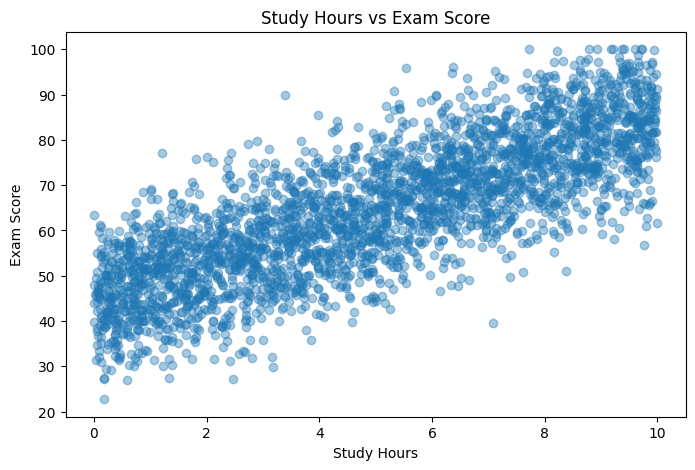

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(df["study_hours"], df["exam_score"], alpha=0.4)
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")
plt.show()

In [8]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values:
study_hours        0
attendance         0
sleep_hours        0
previous_score     0
practice_tests     0
internet_access    0
exam_score         0
dtype: int64
Duplicate rows: 0


In [9]:
X = df.drop("exam_score", axis=1)
y = df["exam_score"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3000, 6)
y shape: (3000,)


In [10]:
X = pd.get_dummies(
    X,
    columns=["internet_access"],
    dtype=int
)

display(X.head())
print(X.shape)

,study_hours,attendance,sleep_hours,previous_score,practice_tests,internet_access_no,internet_access_yes
0,3.75,80.36,7.89,93.09,19,0,1
1,9.51,87.80,5.03,62.03,6,0,1
2,7.32,55.03,9.23,77.99,2,0,1
3,5.99,77.49,7.68,54.88,4,1,0
4,1.56,74.30,4.94,70.40,0,0,1


(3000, 7)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (2400, 7)
Testing features: (600, 7)


In [12]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [13]:
y_pred = model.predict(X_test)

print("First 10 actual scores:")
print(y_test.head(10).values)

print("\nFirst 10 predicted scores:")
print(y_pred[:10].round(2))

First 10 actual scores:
[63.23 45.19 94.74 53.9  60.4  75.15 63.06 89.75 84.88 77.63]

First 10 predicted scores:
[68.63 49.84 84.92 55.38 53.64 80.45 52.69 80.56 77.92 75.35]


In [14]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

MAE: 5.12
RMSE: 6.32
R2 Score: 0.816


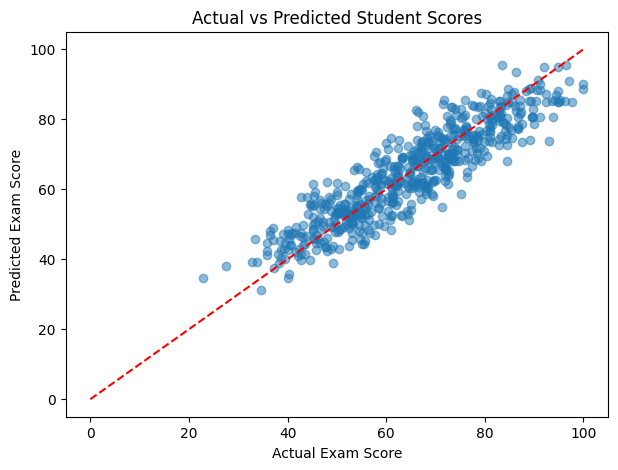

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs Predicted Student Scores")

plt.plot([0, 100], [0, 100], "r--")
plt.show()

In [17]:
student = pd.DataFrame({
    "study_hours": [6],
    "attendance": [85],
    "sleep_hours": [7],
    "previous_score": [70],
    "practice_tests": [5],
    "internet_access": ["yes"]
})

student = pd.get_dummies(
    student,
    columns=["internet_access"],
    dtype=int
)

student = student.reindex(columns=X_train.columns, fill_value=0)

predicted_score = model.predict(student)

print("Predicted Exam Score:", round(predicted_score[0], 2))

Predicted Exam Score: 71.04


In [18]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest RMSE:", round(rf_rmse, 2))
print("Random Forest R2 Score:", round(rf_r2, 3))

Random Forest MAE: 5.54
Random Forest RMSE: 6.92
Random Forest R2 Score: 0.78


In [20]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

display(comparison.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,5.115,6.321,0.816
1,Random Forest,5.545,6.923,0.780


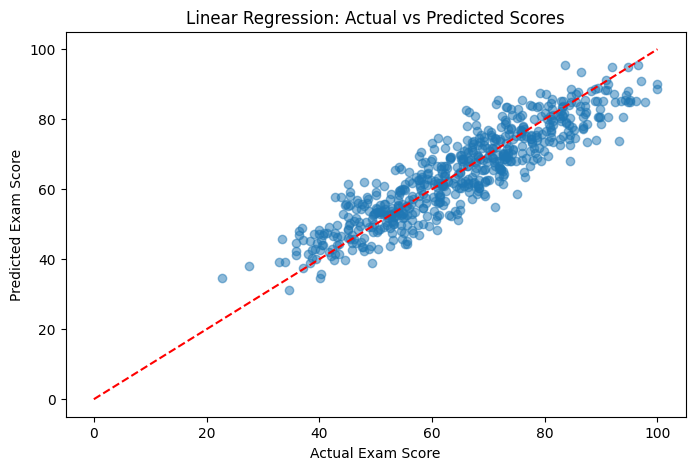

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Linear Regression: Actual vs Predicted Scores")

plt.plot([0, 100], [0, 100], "r--")

plt.show()

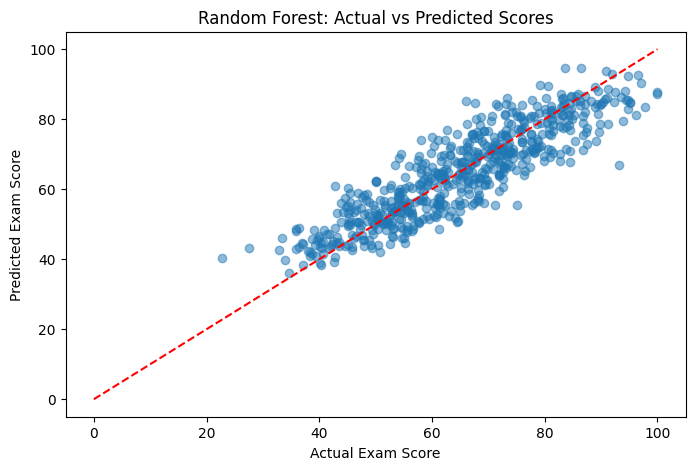

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_predictions, alpha=0.5)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Random Forest: Actual vs Predicted Scores")

plt.plot([0, 100], [0, 100], "r--")

plt.show()


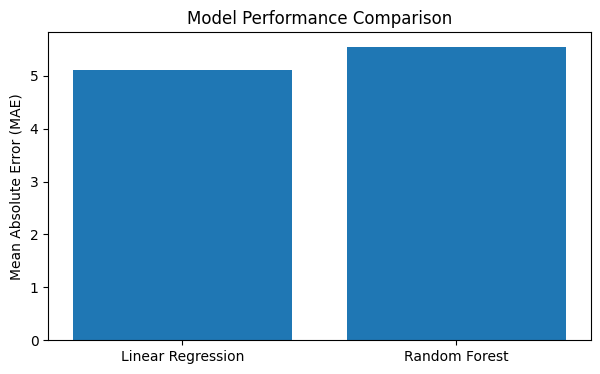

In [23]:
models = ["Linear Regression", "Random Forest"]
mae_scores = [mae, rf_mae]

plt.figure(figsize=(7, 4))
plt.bar(models, mae_scores)

plt.ylabel("Mean Absolute Error (MAE)")
plt.title("Model Performance Comparison")
plt.show()

Linear Regression performed better than Random Forest on the test dataset. It achieved an R² score of 0.816, an MAE of 5.115, and an RMSE of 6.321. This indicates that Linear Regression explains a substantial proportion of the variation in student scores, with an average absolute prediction error of approximately 5.12 marks. Therefore, Linear Regression was selected as the preferred model for this project.

In [24]:
student = pd.DataFrame({
    "study_hours": [6],
    "attendance": [85],
    "sleep_hours": [7],
    "previous_score": [70],
    "practice_tests": [5],
    "internet_access": ["yes"]
})

student = pd.get_dummies(
    student,
    columns=["internet_access"],
    dtype=int
)

student = student.reindex(columns=X_train.columns, fill_value=0)

prediction = model.predict(student)

print("Predicted Exam Score:", round(prediction[0], 2))

Predicted Exam Score: 71.04


In [25]:
from sklearn.metrics import r2_score

y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)

print("Model R2 Score:", round(r2, 3))

Model R2 Score: 0.816
